In [1]:
import numpy as np
import networkx as nx
import scipy.spatial.distance as dist
from scipy.spatial.distance import cdist
from sklearn.neighbors import LocalOutlierFactor

from anomaly_scores import compute_ccof


def test_micro_cluster_isolation():
    # Set seed for exact reproducibility
    np.random.seed(42)
    
    # 1. Primary Normal Cluster: N = 300 points near origin
    X_main = np.random.normal(loc=0.0, scale=1.0, size=(300, 2))
    
    # 2. Micro-Cluster Anomaly: S = 4 points distant from main cluster
    X_micro = np.random.normal(loc=[15.0, 15.0], scale=0.1, size=(4, 2))
    
    # Combine observations
    X = np.vstack([X_main, X_micro])
    k = 10
    
    # Compute CCOF
    ccof_scores, comp_sizes, max_comp_size = compute_ccof(X, k=10)
    
    # Compute LOF for comparison
    lof = LocalOutlierFactor(n_neighbors=k)
    lof.fit(X)
    lof_scores = -lof.negative_outlier_factor_
    
    # Output metrics
    print("==================================================")
    print(" MICRO-CLUSTER ISOLATION SIMULATION (S <= k) ")
    print("==================================================")
    print(f"Primary Cluster Count (N) : 300")
    print(f"Micro-Cluster Count (S)  : 4")
    print(f"Neighborhood Size (k)    : {k}")
    print("--------------------------------------------------")
    print(f"Max Component Size (|C_max|)        : {max_comp_size}")
    print(f"Micro-Cluster Size (|C(i)|)         : {comp_sizes[300]}")
    print(f"Factor 2 Ratio (|C_max| / |C(i)|)  : {max_comp_size / comp_sizes[300]:.1f}")
    print("--------------------------------------------------")
    print("SCORES COMPARISON:")
    print(f"Main Cluster CCOF Mean  : {np.mean(ccof_scores[:300]):.1f}")
    print(f"Micro-Cluster CCOF Mean : {np.mean(ccof_scores[300:]):.1f}")
    print(f"Micro-Cluster CCOF Points: {np.round(ccof_scores[300:], 1)}")
    print("--------------------------------------------------")
    print(f"Main Cluster LOF Mean   : {np.mean(lof_scores[:300]):.3f}")
    print(f"Micro-Cluster LOF Mean  : {np.mean(lof_scores[300:]):.3f}")
    print(f"Micro-Cluster LOF Points : {np.round(lof_scores[300:], 3)}")
    print("==================================================")


if __name__ == "__main__":
    test_micro_cluster_isolation()

 MICRO-CLUSTER ISOLATION SIMULATION (S <= k) 
Primary Cluster Count (N) : 300
Micro-Cluster Count (S)  : 4
Neighborhood Size (k)    : 10
--------------------------------------------------
Max Component Size (|C_max|)        : 304
Micro-Cluster Size (|C(i)|)         : 304
Factor 2 Ratio (|C_max| / |C(i)|)  : 1.0
--------------------------------------------------
SCORES COMPARISON:
Main Cluster CCOF Mean  : 362.9
Micro-Cluster CCOF Mean : 165.3
Micro-Cluster CCOF Points: [165.3 165.2 165.3 165.3]
--------------------------------------------------
Main Cluster LOF Mean   : 1.093
Micro-Cluster LOF Mean  : 15.045
Micro-Cluster LOF Points : [15.025 15.105 15.09  14.962]


In [2]:
np.log(298)/np.log(4)


np.float64(4.109584260231081)

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import scoring functions
from anomaly_scores import score_knn, score_lof, score_loci, score_inflo, score_cof, score_ccof

np.random.seed(123)

n_values = [100, 500, 1000, 5000]
p = 10
k = int(np.log(n_values[-1]))  # Set k based on the largest n value
B = 10  # Repetitions

runtime_list = []

for n in n_values:
    print(f"Running n = {n}")
    for b in range(B):
        X = np.random.normal(size=(n, p))
        
        # KNN
        t0 = time.perf_counter()
        _ = score_knn(X, k)
        t1 = time.perf_counter() - t0
        
        # LOF
        t0 = time.perf_counter()
        _ = score_lof(X, k)
        t2 = time.perf_counter() - t0
        
        # LOCI
        t0 = time.perf_counter()
        _ = score_loci(X, k)
        t3 = time.perf_counter() - t0
        
        # INFLO
        t0 = time.perf_counter()
        _ = score_inflo(X, k)
        t4 = time.perf_counter() - t0

        # COF
        t0 = time.perf_counter()
        _ = score_cof(X, k)
        t5 = time.perf_counter() - t0
        
        # CCOF
        t0 = time.perf_counter()
        _ = score_ccof(X, k)
        t6 = time.perf_counter() - t0
        
        runtime_list.extend([
            {'n': n, 'method': 'KNN', 'time': t1},
            {'n': n, 'method': 'LOF', 'time': t2},
            {'n': n, 'method': 'LOCI', 'time': t3},
            {'n': n, 'method': 'INFLO', 'time': t4},
            {'n': n, 'method': 'COF', 'time': t5},
            {'n': n, 'method': 'CCOF', 'time': t6},
        ])

runtime_df = pd.DataFrame(runtime_list)
runtime_avg = runtime_df.groupby(['n', 'method'], as_index=False)['time'].mean()
print("\nAverage Runtime:")
print(runtime_avg)

Running n = 100
Running n = 500
Running n = 1000
Running n = 5000

Average Runtime:
       n method      time
0    100   CCOF  0.004288
1    100    COF  0.026135
2    100  INFLO  0.003257
3    100    KNN  0.001984
4    100   LOCI  0.013864
5    100    LOF  0.002304
6    500   CCOF  0.080890
7    500    COF  0.195177
8    500  INFLO  0.025580
9    500    KNN  0.007873
10   500   LOCI  0.118143
11   500    LOF  0.021073
12  1000   CCOF  0.221773
13  1000    COF  0.298108
14  1000  INFLO  0.049522
15  1000    KNN  0.027103
16  1000   LOCI  0.141725
17  1000    LOF  0.041474
18  5000   CCOF  7.905138
19  5000    COF  2.740210
20  5000  INFLO  1.319787
21  5000    KNN  1.583611
22  5000   LOCI  1.890218
23  5000    LOF  1.336304


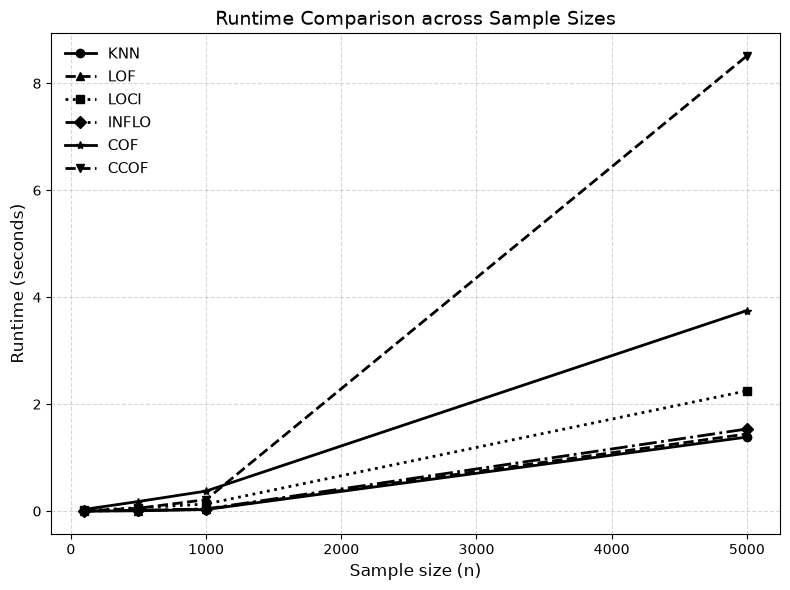

In [4]:

# Plotting runtime curves
methods = ["KNN", "LOF", "LOCI", "INFLO", "COF", "CCOF"]
markers = ['o', '^', 's', 'D', '*', 'v']
linestyles = ['-', '--', ':', '-.', '-', '--']

plt.figure(figsize=(8, 6))
for i, m in enumerate(methods):
    sub = runtime_avg[runtime_avg['method'] == m]
    plt.plot(sub['n'], sub['time'], label=m, marker=markers[i], linestyle=linestyles[i], color='black', linewidth=2)

plt.xlabel("Sample size (n)", fontsize=12)
plt.ylabel("Runtime (seconds)", fontsize=12)
plt.title("Runtime Comparison across Sample Sizes", fontsize=14)
plt.legend(loc="upper left", frameon=False, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("runtime_plot.png", dpi=300)
plt.show()


## plot